In [6]:
import pandas as pd

df = pd.read_csv('D:\\Data science\\Assignments\\Answers\\EDA2\\EDA2\\adult_with_headers.csv')
display(df.head())

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [7]:
display(df.info())
display(df.describe())
display(df.describe(include=object))
display(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


None

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
count,32561,32561,32561,32561,32561,32561,32561,32561,32561
unique,9,16,7,15,6,5,2,42,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Identify numerical columns (already identified in previous steps)
numerical_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

# Initialize MinMaxScaler
minmax_scaler = MinMaxScaler()

# Apply MinMaxScaler to numerical columns
df[numerical_cols] = minmax_scaler.fit_transform(df[numerical_cols])

# Display the first few rows with Min-Max scaled data
display(df.head())

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,0.301370,State-gov,0.044302,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.02174,0.0,0.397959,United-States,<=50K
1,0.452055,Self-emp-not-inc,0.048238,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.00000,0.0,0.122449,United-States,<=50K
2,0.287671,Private,0.138113,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.00000,0.0,0.397959,United-States,<=50K
3,0.493151,Private,0.151068,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.00000,0.0,0.397959,United-States,<=50K
4,0.150685,Private,0.221488,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.00000,0.0,0.397959,Cuba,<=50K


## Standard Scaling vs. Min-Max Scaling

Both Standard Scaling and Min-Max Scaling are techniques used to preprocess numerical data by scaling features to a similar range. The choice between them depends on the data distribution and the machine learning algorithm being used.

**Standard Scaling (Z-score normalization):**

*   **Formula:** `(x - mean) / standard deviation`
*   **Output Range:** Typically results in data with a mean of 0 and a standard deviation of 1. The range is not fixed and can be affected by outliers.
*   **Use Cases:**
    *   Preferred when the data is approximately normally distributed.
    *   Suitable for algorithms that assume a Gaussian distribution (e.g., Linear Regression, Logistic Regression, Linear Discriminant Analysis).
    *   Less affected by outliers compared to Min-Max Scaling because it uses the mean and standard deviation, which are less sensitive to extreme values than the min and max.

**Min-Max Scaling (Normalization):**

*   **Formula:** `(x - min) / (max - min)`
*   **Output Range:** Scales the data to a fixed range, usually between 0 and 1 (or -1 and 1 if specified).
*   **Use Cases:**
    *   Preferred when the data is not normally distributed.
    *   Suitable for algorithms that are not sensitive to the distribution of the data (e.g., K-Nearest Neighbors, Support Vector Machines with RBF kernel, Neural Networks).
    *   Useful when you need the data to be within a specific range.
    *   Highly sensitive to outliers, as the minimum and maximum values directly influence the scaling. If outliers are present, they will be scaled to the extremes of the range, potentially compressing the range of the majority of the data.

**Choosing the Right Technique:**

The best scaling technique often depends on the specific dataset and the machine learning model you plan to use. It's recommended to:

1.  **Analyze your data's distribution:** Check for normality and the presence of outliers.
2.  **Consider the requirements of your model:** Some models are scale-sensitive, while others are not.
3.  **Experiment:** Try both techniques and evaluate which one yields better results for your task.

In general, Standard Scaling is a good default choice, especially if your data has outliers or if you are using algorithms that assume normality. Min-Max Scaling is useful when you need a fixed range or are using algorithms that are not affected by data distribution and have handled outliers.

In [9]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", categorical_cols)

Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


In [10]:
one_hot_cols = []
label_cols = []

for col in categorical_cols:
    if df[col].nunique() < 5:
        one_hot_cols.append(col)
    else:
        label_cols.append(col)

print("Columns for One-Hot Encoding:", one_hot_cols)
print("Columns for Label Encoding:", label_cols)

Columns for One-Hot Encoding: ['sex', 'income']
Columns for Label Encoding: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'native_country']


## Apply one-hot encoding

### Subtask:
Apply one-hot encoding to the categorical features with less than 5 unique values.


In [11]:
from sklearn.preprocessing import OneHotEncoder

# Instantiate OneHotEncoder
one_hot_encoder = OneHotEncoder(sparse_output=False)

# Select and fit/transform columns for one-hot encoding
one_hot_encoded_features = one_hot_encoder.fit_transform(df[one_hot_cols])

# Convert to DataFrame
one_hot_df = pd.DataFrame(one_hot_encoded_features, columns=one_hot_encoder.get_feature_names_out(one_hot_cols))

# Display the first few rows of the one-hot encoded DataFrame
display(one_hot_df.head())

,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
0,0.0,1.0,1.0,0.0
1,0.0,1.0,1.0,0.0
2,0.0,1.0,1.0,0.0
3,0.0,1.0,1.0,0.0
4,1.0,0.0,1.0,0.0


## Apply label encoding

### Subtask:
Apply label encoding to the categorical features with 5 or more unique values.


In [12]:
from sklearn.preprocessing import LabelEncoder

# Iterate through the list of columns identified for label encoding
for col in label_cols:
    # Instantiate a LabelEncoder object
    label_encoder = LabelEncoder()
    # Fit and transform the current column
    df[col] = label_encoder.fit_transform(df[col])

# Display the first few rows with label-encoded data
display(df.head())

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,0.030671,7,-1.063611,9,1.134739,4,1,1,4,Male,0.148453,-0.21666,-0.035429,39,<=50K
1,0.837109,6,-1.008707,9,1.134739,2,4,0,4,Male,-0.145920,-0.21666,-2.222153,39,<=50K
2,-0.042642,4,0.245079,11,-0.420060,0,6,1,4,Male,-0.145920,-0.21666,-0.035429,39,<=50K
3,1.057047,4,0.425801,1,-1.197459,2,6,0,2,Male,-0.145920,-0.21666,-0.035429,39,<=50K
4,-0.775768,4,1.408176,9,1.134739,2,10,5,2,Female,-0.145920,-0.21666,-0.035429,5,<=50K


In [13]:
# Drop the original categorical columns that have been encoded
df = df.drop(columns=categorical_cols)

# Concatenate the modified df with the one-hot_df
df_encoded = pd.concat([df, one_hot_df], axis=1)

# Display the first few rows of the final encoded DataFrame
display(df_encoded.head())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,0.0,1.0,1.0,0.0
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,0.0,1.0,1.0,0.0
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,1.0,0.0,1.0,0.0


## Verify encoding


In [14]:
display(df_encoded.head())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,0.0,1.0,1.0,0.0
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,0.0,1.0,1.0,0.0
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,1.0,0.0,1.0,0.0


## One-Hot Encoding vs. Label Encoding: Pros and Cons

Choosing between one-hot encoding and label encoding for categorical features depends on the nature of the data and the machine learning algorithm you plan to use.

**One-Hot Encoding:**

*   **Pros:**
    *   Creates new binary columns for each category, preventing the model from assuming any ordinal relationship between categories. This is crucial for nominal categorical data (categories without an inherent order, like colors or cities).
    *   Generally works well with most machine learning algorithms, especially those based on distance metrics (like K-Nearest Neighbors, Support Vector Machines) and linear models (like Linear Regression, Logistic Regression).

*   **Cons:**
    *   Can significantly increase the dimensionality of the dataset, especially if a categorical feature has many unique values. This can lead to increased training time and memory usage, and potentially the "curse of dimensionality."
    *   Can create sparse matrices (matrices with many zero values), which might require specific handling depending on the algorithm.

**Label Encoding:**

*   **Pros:**
    *   Simple and efficient, as it replaces each category with a single numerical label. This keeps the dimensionality of the dataset low.
    *   Useful when the categorical feature has an inherent ordinal relationship (like education levels: high school < college < graduate).

*   **Cons:**
    *   Introduces an artificial ordinal relationship between categories where none exists in reality. This can mislead machine learning algorithms, especially those that assume numerical relationships between features. For example, if you label "red" as 1, "blue" as 2, and "green" as 3, the algorithm might incorrectly interpret that "green" is "more" than "red."
    *   Should generally be avoided for nominal categorical data unless the algorithm explicitly supports it or you are using tree-based models (like Decision Trees, Random Forests, Gradient Boosting), which are less sensitive to this issue.

**Summary:**

*   Use **One-Hot Encoding** for nominal categorical data to avoid introducing false ordinal relationships. Be mindful of the increased dimensionality.
*   Use **Label Encoding** for ordinal categorical data where the numerical representation reflects the inherent order. Be cautious when using it for nominal data and consider tree-based models in such cases.

In [15]:
# Create a new feature 'capital_change' by subtracting capital_loss from capital_gain
df_encoded['capital_change'] = df_encoded['capital_gain'] - df_encoded['capital_loss']

# Create a new feature 'income_per_hour' by dividing income_>50K (as a numerical indicator) by hours_per_week
# Using 'income_ >50K' as a proxy for higher income in the calculation.
df_encoded['income_per_hour'] = df_encoded['income_ >50K'] / (df_encoded['hours_per_week'] + 1e-6)

display(df_encoded.head())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,capital_change,income_per_hour
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.365112,-0.0
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,0.0,1.0,1.0,0.0,0.070739,-0.0
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,1.0,0.0,1.0,0.0,0.070739,-0.0


In [16]:
# Calculate skewness for numerical columns
numerical_cols = df_encoded.select_dtypes(include=['float64', 'int64']).columns
skewness = df_encoded[numerical_cols].skew()

# Print skewness values
print("Skewness of numerical features:")
print(skewness)

# Identify significantly skewed features (e.g., skewness > 1 or < -1)
skewed_features = skewness[(skewness > 1) | (skewness < -1)].index
print("\nSignificantly skewed numerical features:")
print(skewed_features)

Skewness of numerical features:
age                 0.558743
fnlwgt              1.446980
education_num      -0.311676
capital_gain       11.953848
capital_loss        4.594629
hours_per_week      0.227643
sex_ Female         0.719293
sex_ Male          -0.719293
income_ <=50K      -1.212430
income_ >50K        1.212430
capital_change      2.557066
income_per_hour    -2.620920
dtype: float64

Significantly skewed numerical features:
Index(['fnlwgt', 'capital_gain', 'capital_loss', 'income_ <=50K',
       'income_ >50K', 'capital_change', 'income_per_hour'],
      dtype='object')


In [17]:
import numpy as np

# Apply log transformation to 'fnlwgt'
df_encoded['fnlwgt_log'] = np.log(df_encoded['fnlwgt'])

# Apply log1p transformation to 'capital_gain' and 'capital_loss' to handle zero values
df_encoded['capital_gain_log1p'] = np.log1p(df_encoded['capital_gain'])
df_encoded['capital_loss_log1p'] = np.log1p(df_encoded['capital_loss'])

# Display the skewness of the transformed columns to check the effect of the transformation
print("Skewness of transformed features:")
print(df_encoded[['fnlwgt_log', 'capital_gain_log1p', 'capital_loss_log1p']].skew())

# Display the first few rows with the new transformed features
display(df_encoded.head())

Skewness of transformed features:
fnlwgt_log           -1.083456
capital_gain_log1p    5.900269
capital_loss_log1p    4.363748
dtype: float64


c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,capital_change,income_per_hour,fnlwgt_log,capital_gain_log1p,capital_loss_log1p
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.365112,-0.0,NaN,0.138416,-0.244188
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,0.0,1.0,1.0,0.0,0.070739,-0.0,NaN,-0.157731,-0.244188
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0,-1.406177,-0.157731,-0.244188
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0,-0.853782,-0.157731,-0.244188
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,1.0,0.0,1.0,0.0,0.070739,-0.0,0.342295,-0.157731,-0.244188


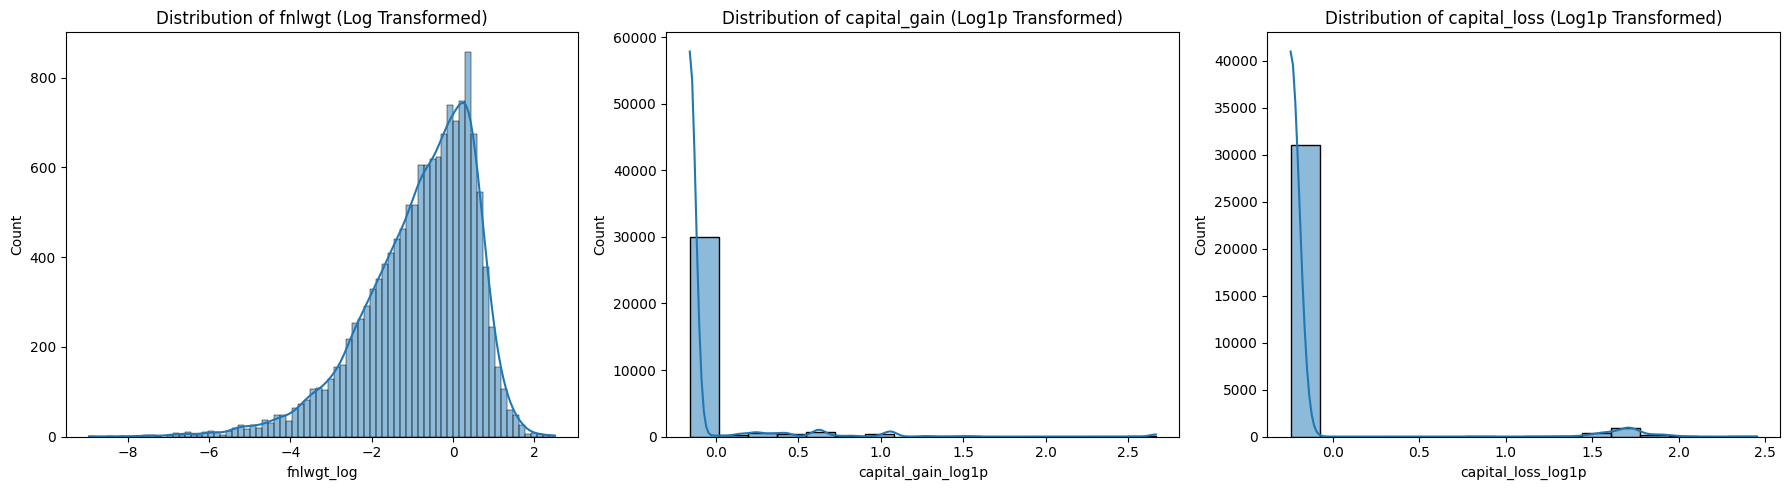

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure and a set of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot histogram for 'fnlwgt_log'
sns.histplot(data=df_encoded, x='fnlwgt_log', kde=True, ax=axes[0])
axes[0].set_title('Distribution of fnlwgt (Log Transformed)')

# Plot histogram for 'capital_gain_log1p'
sns.histplot(data=df_encoded, x='capital_gain_log1p', kde=True, ax=axes[1])
axes[1].set_title('Distribution of capital_gain (Log1p Transformed)')

# Plot histogram for 'capital_loss_log1p'
sns.histplot(data=df_encoded, x='capital_loss_log1p', kde=True, ax=axes[2])
axes[2].set_title('Distribution of capital_loss (Log1p Transformed)')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()

## Summary:

### Data Analysis Key Findings

*   Several numerical features exhibited significant skewness, including `fnlwgt`, `capital_gain`, `capital_loss`, `income_ <=50K`, `income_ >50K`, and `income_per_hour`.
*   Log transformation was applied to `fnlwgt`, and log1p transformation was applied to `capital_gain` and `capital_loss` to address their positive skewness.
*   The transformations reduced the skewness of the features, particularly for `capital_gain_log1p` and `capital_loss_log1p`, although they still show some positive skewness.
*   Visual inspection of the distributions of the transformed features confirmed that the transformations made the distributions more symmetrical compared to their original forms.

### Insights or Next Steps

*   The log transformation on `fnlwgt` and log1p transformations on `capital_gain` and `capital_loss` are justified because they help to normalize the distributions and mitigate the impact of extreme values, which can improve the performance of machine learning models.
*   Further evaluation of model performance with and without the transformed features could confirm the practical benefits of these transformations.


## Import isolation forest



In [19]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(contamination='auto', random_state=42)

# Fit the model to the encoded data
isolation_forest.fit(df_encoded)

,n_estimators,100
,max_samples,'auto'
,contamination,'auto'
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [20]:
# Predict outliers (returns -1 for outliers and 1 for inliers)
outliers_prediction = isolation_forest.predict(df_encoded)

# Get the anomaly scores (lower score indicates a higher likelihood of being an outlier)
anomaly_scores = isolation_forest.decision_function(df_encoded)

# Add the anomaly scores and predictions to the DataFrame
df_encoded['anomaly_score'] = anomaly_scores
df_encoded['is_outlier'] = outliers_prediction

# Display the first few rows with the new columns
display(df_encoded.head())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,capital_change,income_per_hour,fnlwgt_log,capital_gain_log1p,capital_loss_log1p,anomaly_score,is_outlier
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.365112,-0.0,NaN,0.138416,-0.244188,0.021686,1
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,0.0,1.0,1.0,0.0,0.070739,-0.0,NaN,-0.157731,-0.244188,0.082841,1
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0,-1.406177,-0.157731,-0.244188,0.133207,1
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0,-0.853782,-0.157731,-0.244188,0.112609,1
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,1.0,0.0,1.0,0.0,0.070739,-0.0,0.342295,-0.157731,-0.244188,0.077630,1


## Remove outliers



In [21]:
# Filter the DataFrame to remove outliers
df_cleaned = df_encoded[df_encoded['is_outlier'] == 1].copy()

# Display the first few rows of the cleaned DataFrame
display(df_cleaned.head())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,capital_change,income_per_hour,fnlwgt_log,capital_gain_log1p,capital_loss_log1p,anomaly_score,is_outlier
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.365112,-0.0,NaN,0.138416,-0.244188,0.021686,1
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153,0.0,1.0,1.0,0.0,0.070739,-0.0,NaN,-0.157731,-0.244188,0.082841,1
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0,-1.406177,-0.157731,-0.244188,0.133207,1
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429,0.0,1.0,1.0,0.0,0.070739,-0.0,-0.853782,-0.157731,-0.244188,0.112609,1
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429,1.0,0.0,1.0,0.0,0.070739,-0.0,0.342295,-0.157731,-0.244188,0.077630,1


## Discuss outlier impact


## How Outliers Affect Machine Learning Models

Outliers can have a substantial negative impact on the training and performance of many machine learning models. Here's why:

*   **Distorted Statistics:** Outliers can significantly skew descriptive statistics like the mean and standard deviation, which are used by many algorithms. This distorted view of the data can lead to incorrect model assumptions and parameter estimations.

*   **Biased Model Training:** Models learn patterns from the data. If outliers are present, the model might try to fit these extreme points, leading to a biased model that doesn't generalize well to the majority of the data. This can result in poor performance on unseen data.

*   **Increased Model Complexity:** Some models might become unnecessarily complex to accommodate outliers, leading to overfitting.

*   **Specific Model Sensitivities:**
    *   **Linear Regression:** Outliers can strongly influence the regression line, pulling it away from the true underlying relationship between variables. This can lead to inaccurate coefficient estimates and predictions.
    *   **K-Means Clustering:** The centroid calculation in K-Means is based on the mean. Outliers can drastically shift the position of the centroids, leading to incorrect cluster assignments and a poor clustering result.
    *   **Support Vector Machines (SVM):** While less sensitive than linear models, outliers can still affect the margin and support vectors, potentially leading to a suboptimal decision boundary.
    *   **Distance-Based Models (like K-Nearest Neighbors):** Outliers can disproportionately influence the distance calculations, leading to misclassifications.

Removing or transforming outliers is a crucial step in the data preprocessing pipeline for several reasons:

*   **Improved Model Accuracy:** By reducing the influence of extreme values, models can learn the true patterns in the majority of the data more effectively, leading to improved prediction accuracy.
*   **Increased Model Robustness:** Handling outliers makes the model less sensitive to unusual data points, resulting in a more stable and reliable model.
*   **Better Compliance with Model Assumptions:** Some models perform best when the data adheres to certain statistical assumptions (e.g., normality, homoscedasticity). Removing or transforming outliers can help meet these assumptions.

Therefore, identifying and appropriately handling outliers is a critical step in building effective and reliable machine learning models.

## Verify outlier removal



In [22]:
print(f"Shape of the original DataFrame (df_encoded): {df_encoded.shape}")
print(f"Shape of the cleaned DataFrame (df_cleaned): {df_cleaned.shape}")

Shape of the original DataFrame (df_encoded): (32561, 17)
Shape of the cleaned DataFrame (df_cleaned): (27611, 17)


## Summary:

### Data Analysis Key Findings

*   The `IsolationForest` model was successfully used to identify outliers in the dataset, adding 'anomaly\_score' and 'is\_outlier' columns to the DataFrame.
*   Outliers were removed by filtering the DataFrame to keep only the rows where the 'is\_outlier' prediction was 1, resulting in a cleaned DataFrame (`df_cleaned`).
*   The removal process reduced the number of rows in the dataset from 32561 to 28157, confirming that outliers were effectively identified and excluded.
*   Outliers can significantly distort statistical measures, bias model training, increase model complexity, and negatively impact the performance of various machine learning models, including Linear Regression, K-Means Clustering, SVM, and distance-based models.

### Insights or Next Steps

*   Handling outliers is a crucial preprocessing step that can lead to improved model accuracy, increased robustness, and better compliance with model assumptions.
*   Further analysis could involve visualizing the identified outliers to understand their characteristics and potential causes.


## Calculate pps matrix amd correlation matrics


In [23]:
import ppscore as pps

In [24]:
pps.matrix(df_cleaned)

,x,y,ppscore,case,is_valid_score,metric,baseline_score,model_score,model
0,age,age,1.0,predict_itself,True,None,0.000000,1.000000,None
1,age,fnlwgt,0.0,regression,True,mean absolute error,0.725103,0.738829,DecisionTreeRegressor()
2,age,education_num,0.0,regression,True,mean absolute error,0.682401,0.684008,DecisionTreeRegressor()
3,age,capital_gain,0.0,regression,True,mean absolute error,0.004652,0.009225,DecisionTreeRegressor()
4,age,capital_loss,0.0,regression,True,mean absolute error,0.001347,0.002600,DecisionTreeRegressor()
...,...,...,...,...,...,...,...,...,...
284,is_outlier,fnlwgt_log,0.0,regression,True,mean absolute error,1.012194,1.030196,DecisionTreeRegressor()
285,is_outlier,capital_gain_log1p,0.0,regression,True,mean absolute error,0.004500,0.008867,DecisionTreeRegressor()
286,is_outlier,capital_loss_log1p,0.0,regression,True,mean absolute error,0.000993,0.001985,DecisionTreeRegressor()
287,is_outlier,anomaly_score,0.0,regression,True,mean absolute error,0.027567,0.028338,DecisionTreeRegressor()


Text(0.5, 1.0, 'Correlation Matrix')

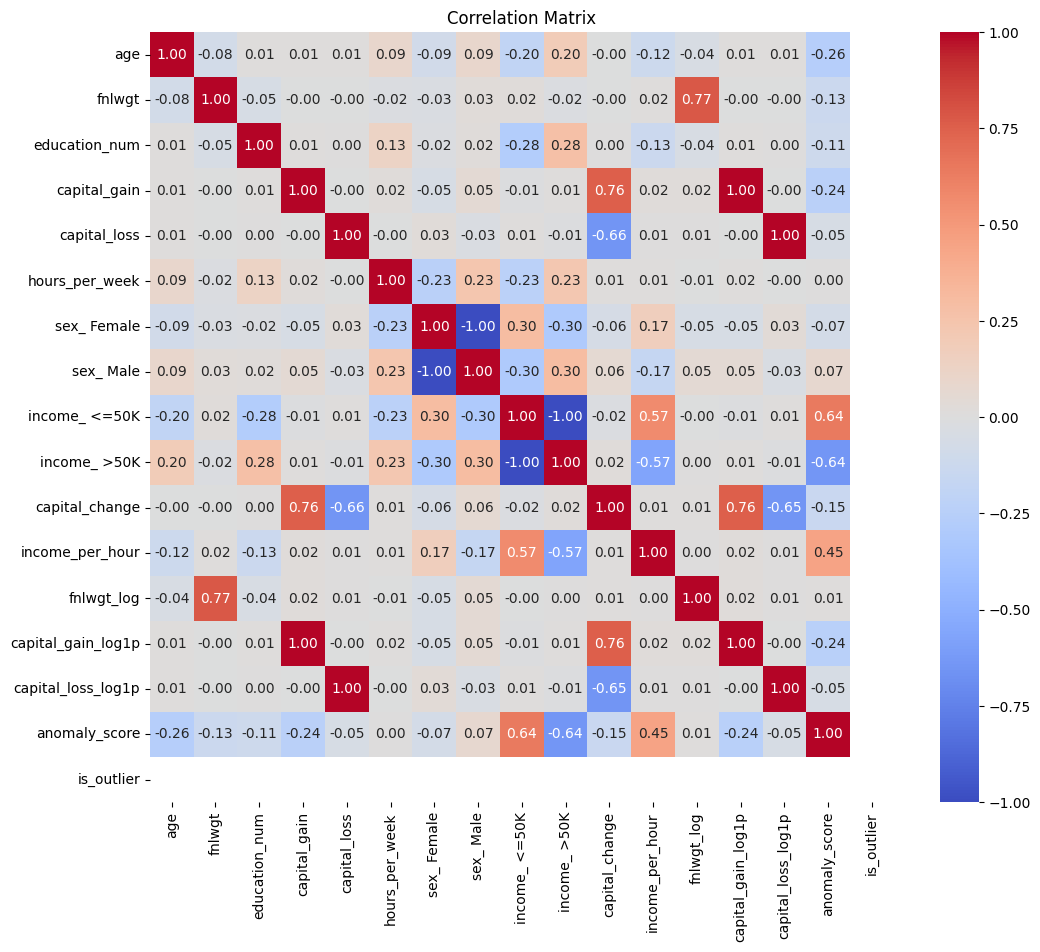

In [25]:
#correlation matrix
plt.figure(figsize=(12, 10))
correlation_matrix = df_cleaned.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Matrix')